In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.neural_network import MLPRegressor
import time
from sklearn.model_selection import GroupKFold
import seaborn as sns
from sklearn.dummy import DummyRegressor
from airfoil_utils import make_mlp, regression_metrics

pd.set_option("display.precision", 4)

Load data and define inputs and outpus

In [2]:
col_names=['Frequency_Hz','Angle_of_attack_deg','Chord_length_m','Free_stream_velocity_m/s','Suction_side_displacement_thickness_m','Scaled_sound_pressure_level_dB']
df = pd.read_csv(
    "../data/airfoil_self_noise.dat",
    sep=r"\s+",
    header=None,
    names=col_names
)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)
print(df.head())

X = df.iloc[:, 0:5]
y = df.iloc[:, 5]



   Frequency_Hz  Angle_of_attack_deg  Chord_length_m  Free_stream_velocity_m/s  Suction_side_displacement_thickness_m  Scaled_sound_pressure_level_dB
0           800                  0.0          0.3048                      71.3                                 0.0027                         126.201
1          1000                  0.0          0.3048                      71.3                                 0.0027                         125.201
2          1250                  0.0          0.3048                      71.3                                 0.0027                         125.951
3          1600                  0.0          0.3048                      71.3                                 0.0027                         127.591
4          2000                  0.0          0.3048                      71.3                                 0.0027                         127.461


Data cleaning

In [3]:
#Check the basic structure of data
print("Shape: ")
print("DataFrame shape: ",df.shape)
print("X shape: ",X.shape)
print("Y shape: ",y.shape)
print("------------------------------------------")
#Check data type for each entry
print("Data type:\n",df.dtypes,sep="")
print("------------------------------------------")
#Chek missing values
print("Missing value count:\n",df.isnull().sum(),sep="")
print("------------------------------------------")
#Check duplicated rows
print("Duplicated rows:",df.duplicated().sum())
print("------------------------------------------")
#Check the overall statistics of data
print(df.describe())

Shape: 
DataFrame shape:  (1503, 6)
X shape:  (1503, 5)
Y shape:  (1503,)
------------------------------------------
Data type:
Frequency_Hz                               int64
Angle_of_attack_deg                      float64
Chord_length_m                           float64
Free_stream_velocity_m/s                 float64
Suction_side_displacement_thickness_m    float64
Scaled_sound_pressure_level_dB           float64
dtype: object
------------------------------------------
Missing value count:
Frequency_Hz                             0
Angle_of_attack_deg                      0
Chord_length_m                           0
Free_stream_velocity_m/s                 0
Suction_side_displacement_thickness_m    0
Scaled_sound_pressure_level_dB           0
dtype: int64
------------------------------------------
Duplicated rows: 0
------------------------------------------
       Frequency_Hz  Angle_of_attack_deg  Chord_length_m  Free_stream_velocity_m/s  Suction_side_displacement_thickness_m  S

Split the data into train, validation and test set using group split becasue the experiment is about obtaining a spectrum of frequency, then analyze their spl, for different type of NACA0012 sizes and angle of attack. 

In [4]:
categorical_feature = ['Angle_of_attack_deg','Chord_length_m','Free_stream_velocity_m/s','Suction_side_displacement_thickness_m']
#Take the value of the categorical_feature column and convert them into a tuple. Assign each unique tuple (unique) with an ID (groups).
groups, unique = pd.factorize(X[categorical_feature].apply(tuple, axis=1))

#Split data into train, validation and test set, ratio of 60:20:20
#Use Group Split to split data once into train+validation and test set, ratio of 80:20
gss_test = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
#Split the data and obtain the row idx for train_validation and test set
train_val_idx, test_idx = next(gss_test.split(X, y, groups=groups))

#Extract the data to their corresponding idx
X_train_val, X_test = X.iloc[train_val_idx], X.iloc[test_idx]
y_train_val, y_test = y.iloc[train_val_idx], y.iloc[test_idx]

#Use same procedure split train and validation set, ratio of 25:75
gss_val = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
#Split the data and obtain the row idx for train and validation set
train_idx, val_idx = next(gss_val.split(X_train_val, y_train_val, groups=groups[train_val_idx]))
#Extract the data to their corresponding idx
X_train, X_val = X_train_val.iloc[train_idx], X_train_val.iloc[val_idx]
y_train, y_val= y_train_val.iloc[train_idx], y_train_val.iloc[val_idx]

Fit Linear Regression to fit data

In [5]:
#Train Linear Regression model
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

#Report the intercept and coefficient in a data frame
coefficient_table = pd.DataFrame({
    "parameter": ['intercept', 'Frequency', 'Angle_of_attack_deg','Chord_length_m','Free_stream_velocity_m/s','Suction_side_displacement_thickness_m'],
    "value": [linear_model.intercept_.item()] + list(linear_model.coef_.ravel()),
    "units": ["dB", "dB/Hz", "dB/deg", "dB/m", "dBs/m", "dB/m"],
})

display(coefficient_table)


#Make prediction on validation set
val_pred_lr = linear_model.predict(X_val)
validation_results = X_val.copy()
#calculate and observe residuals
validation_results["observed_Scaled_sound_pressure_level_dB"] = y_val
validation_results["predicted_Scaled_sound_pressure_level_dB"] = val_pred_lr
validation_results["residual_dB"] = (
    validation_results["observed_Scaled_sound_pressure_level_dB"]
    - validation_results["predicted_Scaled_sound_pressure_level_dB"]
)

display(validation_results)


baseline_prediction = np.full(
    shape=len(y_val),
    fill_value=y_train.mean(),
)

metric_comparison = pd.DataFrame({
    "linear regression": regression_metrics(
        y_val,
        val_pred_lr,
    ),
    "mean baseline": regression_metrics(
        y_val,
        baseline_prediction,
    ),
}).T



,parameter,value,units
0,intercept,131.1134,dB
1,Frequency,-0.0013,dB/Hz
2,Angle_of_attack_deg,-0.3314,dB/deg
3,Chord_length_m,-32.5883,dB/m
4,Free_stream_velocity_m/s,0.1158,dBs/m
5,Suction_side_displacement_thickness_m,-147.0578,dB/m


,Frequency_Hz,Angle_of_attack_deg,Chord_length_m,Free_stream_velocity_m/s,Suction_side_displacement_thickness_m,observed_Scaled_sound_pressure_level_dB,predicted_Scaled_sound_pressure_level_dB,residual_dB
14,500,0.0,0.3048,55.5,0.0028,126.416,126.5437,-0.1277
15,630,0.0,0.3048,55.5,0.0028,127.696,126.3747,1.3213
16,800,0.0,0.3048,55.5,0.0028,128.086,126.1537,1.9323
17,1000,0.0,0.3048,55.5,0.0028,126.966,125.8938,1.0722
18,1250,0.0,0.3048,55.5,0.0028,126.086,125.5688,0.5172
...,...,...,...,...,...,...,...,...
1468,2500,12.3,0.1016,31.7,0.0419,110.317,117.9901,-7.6731
1469,3150,12.3,0.1016,31.7,0.0419,110.307,117.1451,-6.8381
1470,4000,12.3,0.1016,31.7,0.0419,108.407,116.0402,-7.6332
1471,5000,12.3,0.1016,31.7,0.0419,107.147,114.7402,-7.5932


Use Neural Network Regression to fit data

In [6]:

#Define dictionary placeholder to place data of unscaled and scaled MLP
scaling_models = {
    "Unscaled MLP": make_mlp(),
    "Scaled MLP pipeline": make_pipeline(StandardScaler(), make_mlp()),
}

# Calculate performance data for scaled and unscaled MLP
for label, model in scaling_models.items():
    model.fit(X_train, y_train)


Comparison of Mean, Linear Regression and Neural Network Regression metrics.

----Metrics for validation set----


,MAE,RMSE,R2
mean baseline,5.5165,6.8255,-0.0001
linear regression,3.8189,4.8170,0.5019
Unscaled MLP,16.5959,19.8170,-7.4307
Scaled MLP pipeline,2.8957,4.0437,0.6490


----Metrics for train set----


,MAE,RMSE,R2
mean baseline,5.6110,6.8409,0.0000
linear regression,3.7376,4.7697,0.5139
Unscaled MLP,11.3014,13.9908,-3.1827
Scaled MLP pipeline,2.1775,2.9819,0.8100


--- Generalization Gap Table (Validation minus Train) ---


,MAE,RMSE,R2
mean baseline,-0.0946,-0.0154,-0.0001
linear regression,0.0813,0.0473,-0.0120
Unscaled MLP,5.2944,5.8262,-4.2480
Scaled MLP pipeline,0.7182,1.0618,-0.1610


C:\Users\User\AppData\Local\Temp\ipykernel_32628\2262996764.py:103: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=15, ha="right")
findfont: Failed to find font weight semibold, now using 700.


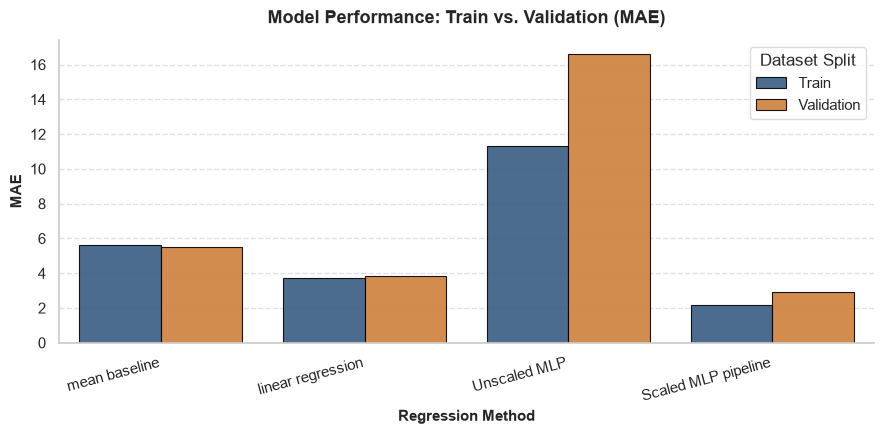

C:\Users\User\AppData\Local\Temp\ipykernel_32628\2262996764.py:103: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=15, ha="right")


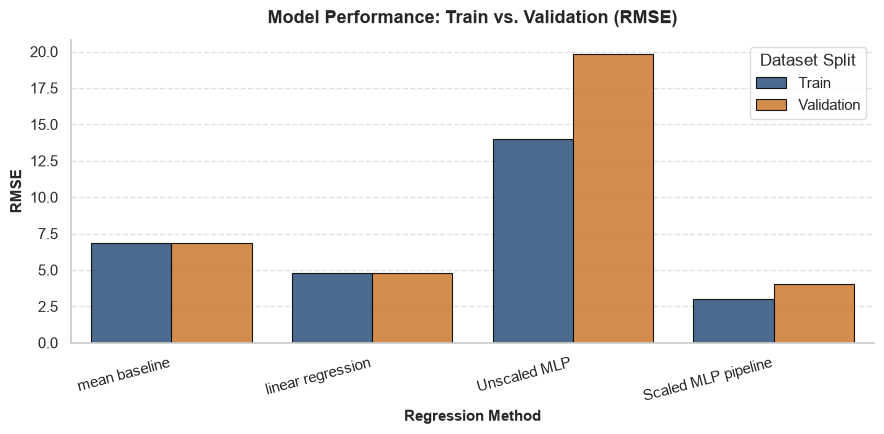

C:\Users\User\AppData\Local\Temp\ipykernel_32628\2262996764.py:103: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=15, ha="right")


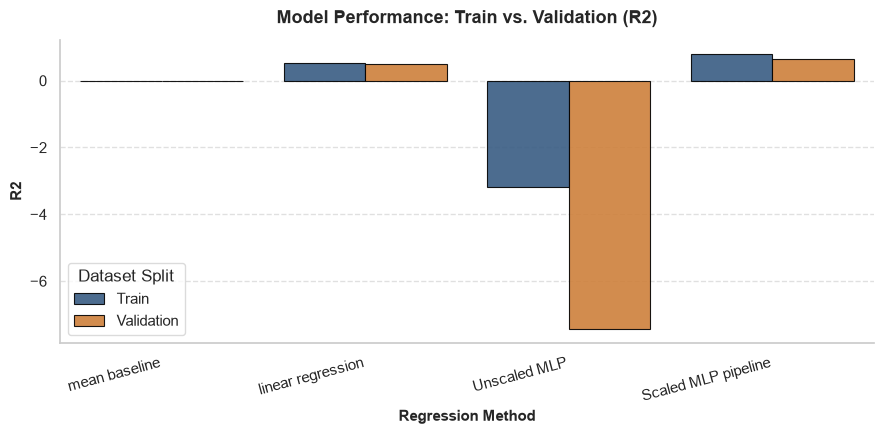

In [7]:
#Do metric comparison for validation data set
metric_comparison_val = pd.DataFrame({
    "mean baseline": regression_metrics(
        y_val,
        baseline_prediction,
    ),
    "linear regression": regression_metrics(
        y_val,
        val_pred_lr,
    ),
    "Unscaled MLP": regression_metrics(
        y_val,
        scaling_models["Unscaled MLP"].predict(X_val),
    ),
    "Scaled MLP pipeline": regression_metrics(
        y_val,
        scaling_models["Scaled MLP pipeline"].predict(X_val),
    ),
}).T
print("----Metrics for validation set----")
display(metric_comparison_val)

#Do metric comparison for train data set
metric_comparison_train = pd.DataFrame({
    "mean baseline": regression_metrics(
        y_train,
        np.full(len(y_train), y_train.mean()),
    ),
    "linear regression": regression_metrics(
        y_train,
        linear_model.predict(X_train),
    ),
    "Unscaled MLP": regression_metrics(
        y_train,
        scaling_models["Unscaled MLP"].predict(X_train),
    ),
    "Scaled MLP pipeline": regression_metrics(
        y_train,
        scaling_models["Scaled MLP pipeline"].predict(X_train),
    ),
}).T
print("----Metrics for train set----")
display(metric_comparison_train)

#Plot graphs to compare the performance value of train and validation data for each method
# 1. Extract the list of metric names
metrics_compare = metric_comparison_train.columns

# 2. Calculate the Generalization Gap Table directly from the separate tables
gap_table = pd.DataFrame(index=metric_comparison_train.index)
for m in metrics_compare:
    # Directly subtract train from validation using the individual DataFrames
    gap_table[m] = metric_comparison_val[m] - metric_comparison_train[m]

print("--- Generalization Gap Table (Validation minus Train) ---")
display(gap_table)

# 3. Loop through each metric and plot side-by-side histograms (bar charts)
# Apply a clean Seaborn style
sns.set_theme(style="whitegrid")

# 3. Loop through each metric and plot side-by-side bar charts using Seaborn
for m in metrics_compare:
  fig, ax = plt.subplots(figsize=(9, 4.5))

  # Bundle Train and Validation metrics for the current metric
  plot_df = pd.DataFrame({
      "Train": metric_comparison_train[m],
      "Validation": metric_comparison_val[m],
  })

  # RESHAPE FOR SEABORN: Convert wide-form to long-form format
  melted_df = (
      plot_df.reset_index()
      .rename(columns={"index": "Model"})
      .melt(id_vars="Model", var_name="Dataset Split", value_name=m)
  )

  # Plot using Seaborn's barplot for a modern aesthetic
  sns.barplot(
      data=melted_df,
      x="Model",
      y=m,
      hue="Dataset Split",
      palette=["#2b5c8f", "#e67e22"],  # Professional blue and orange contrast
      ax=ax,
      edgecolor="black",  # Crisp border lines on the bars
      linewidth=0.8,
      alpha=0.9,
  )

  # Aesthetics and Layout Tweaks
  ax.set_title(
      f"Model Performance: Train vs. Validation ({m})",
      fontsize=13,
      fontweight="bold",
      pad=12,
  )
  ax.set_ylabel(m, fontsize=11, fontweight="semibold")
  ax.set_xlabel("Regression Method", fontsize=11, fontweight="semibold")

  # Rotate x-tick labels slightly if model names are long
  ax.set_xticklabels(ax.get_xticklabels(), rotation=15, ha="right")

  # Clean legend placement
  ax.legend(
      title="Dataset Split",
      frameon=True,
      facecolor="white",
      edgecolor="lightgray",
  )
  ax.grid(axis="y", linestyle="--", alpha=0.6)

  # Remove unnecessary top and right borders (clean academic look)
  sns.despine(top=True, right=True)

  plt.tight_layout()
  plt.show()

Conduct different experiment set using cross validation

---- Validation Metrics for Each Fold ----


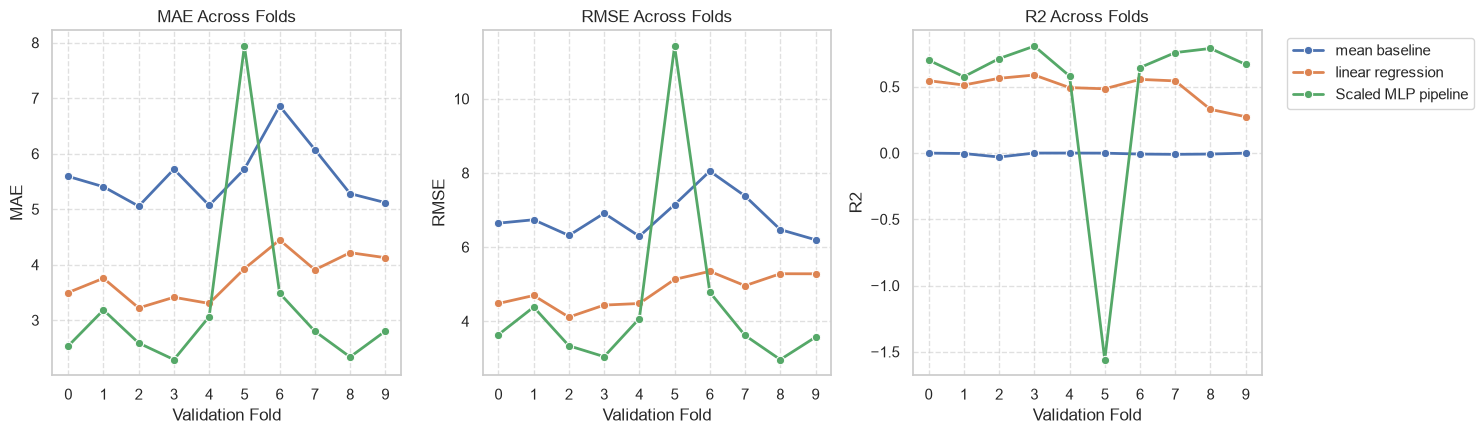


---- Final Averaged Validation Metrics Across All Folds ----


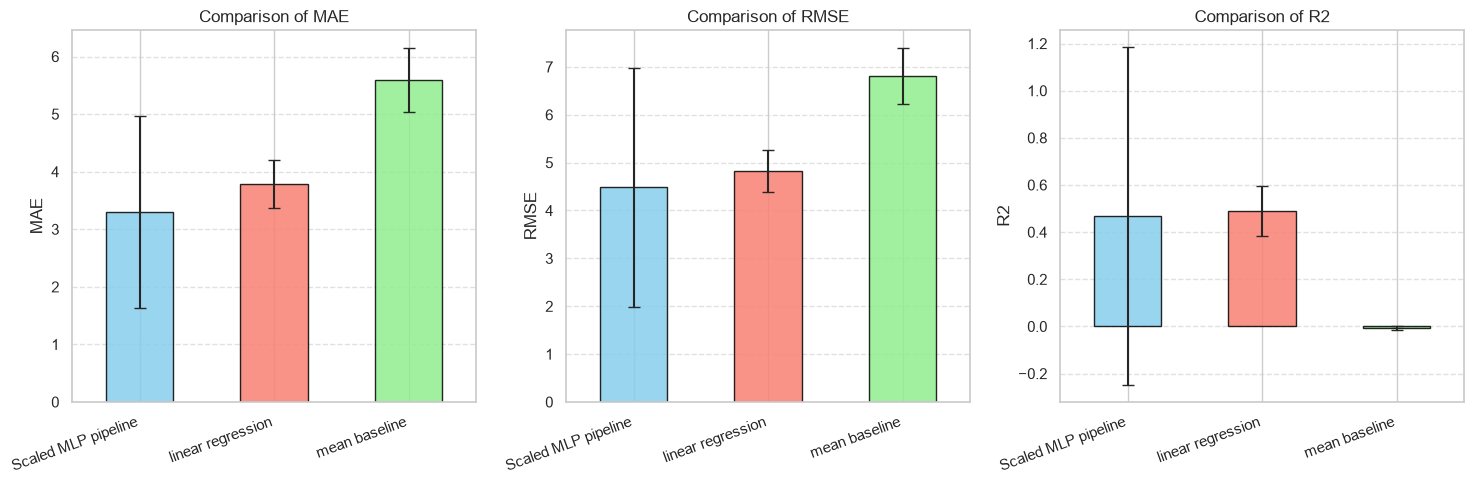

In [8]:
gkf = GroupKFold(n_splits=10)

all_val_metrics = []

for fold, (train_new_idx, val_new_idx) in enumerate(gkf.split(X_train_val, y_train_val, groups=groups[train_val_idx])):
    #Extract the data to their corresponding idx
    X_new_train, X_new_val = X_train_val.iloc[train_new_idx], X_train_val.iloc[val_new_idx]
    y_new_train, y_new_val= y_train_val.iloc[train_new_idx], y_train_val.iloc[val_new_idx]
    
    #refresh baseline
    baseline_pred = np.full(len(y_new_val), y_new_train.mean())
    
    #refresh linear regression
    linear_model_new = LinearRegression()
    linear_model_new.fit(X_new_train, y_new_train)
    
    #refresh neural network regression
    for label_new, model_new in scaling_models.items():
        model_new.fit(X_new_train, y_new_train)
    
    #construct the metric table for validation data set
    metric_comparison_val_new = pd.DataFrame({
        "mean baseline": regression_metrics(
            y_new_val,
            baseline_pred,
        ),
        "linear regression": regression_metrics(
            y_new_val,
            linear_model_new.predict(X_new_val),
        ),
        
        "Scaled MLP pipeline": regression_metrics(
            y_new_val,
            scaling_models["Scaled MLP pipeline"].predict(X_new_val),
        ),
    }).T
    
    #append to list
    all_val_metrics.append(metric_comparison_val_new)

print("---- Validation Metrics for Each Fold ----")
# display(pd.concat(all_val_metrics, keys=range(5)))

# 1. Combine all folds into a single DataFrame keeping the fold keys
full_cv_df = pd.concat(all_val_metrics, keys=range(10))
# The index is currently a MultiIndex: (Fold, Model Name)
full_cv_df.index.names = ["Fold", "Model"]
full_cv_df = full_cv_df.reset_index()

# 2. Get list of metrics (columns excluding 'Fold' and 'Model')
metrics = [col for col in full_cv_df.columns if col not in ["Fold", "Model"]]
n_metrics = len(metrics)

# 3. Create subplots (one per metric)
fig, axes = plt.subplots(1, n_metrics, figsize=(5 * n_metrics, 4.5), sharex=True)
if n_metrics == 1:
  axes = [axes]

for i, metric in enumerate(metrics):
  ax = axes[i]

  # Line plot tracking performance across folds for each model
  sns.lineplot(
      data=full_cv_df,
      x="Fold",
      y=metric,
      hue="Model",
      marker="o",
      linewidth=2,
      ax=ax,
  )

  ax.set_title(f"{metric} Across Folds")
  ax.set_xlabel("Validation Fold")
  ax.set_ylabel(metric)
  ax.set_xticks([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])
  ax.grid(True, linestyle="--", alpha=0.6)

  # Move legend outside or simplify for clarity
  if i == n_metrics - 1:
    ax.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
  else:
    ax.get_legend().remove()

plt.tight_layout()
plt.show()
    
# Average the results across all folds
# pd.concat stacks them, groupby(level=-1).mean() averages the metrics per model
final_averaged_metrics = pd.concat(all_val_metrics).groupby(level=0).mean()

print("\n---- Final Averaged Validation Metrics Across All Folds ----")
# display(final_averaged_metrics)

final_std_metrics = pd.concat(all_val_metrics).groupby(level=0).std()

#print("\n---- Std of Validation Metrics Across All Folds ----")
# display(final_std_metrics)

# Assuming final_averaged_metrics and final_std_metrics have Models as rows and Metrics as columns
# (If your orientation is flipped, you may need to transpose them with .T)

# Determine number of metrics (columns)
metrics = final_averaged_metrics.columns
n_metrics = len(metrics)

# Create subplots side-by-side (one plot per metric)
fig, axes = plt.subplots(1, n_metrics, figsize=(5 * n_metrics, 5), sharex=False)

# Handle case where there's only 1 metric (axes won't be an array)
if n_metrics == 1:
  axes = [axes]

for i, metric in enumerate(metrics):
  ax = axes[i]

  # Extract mean and std for this specific metric
  means = final_averaged_metrics[metric]
  stds = final_std_metrics[metric]

  # Plot bar chart with error bars
  means.plot(
      kind="bar",
      yerr=stds,
      ax=ax,
      capsize=4,
      color=["skyblue", "salmon", "lightgreen"],
      edgecolor="black",
      alpha=0.85,
  )

  ax.set_title(f"Comparison of {metric}")
  ax.set_ylabel(metric)
  ax.set_xticklabels(means.index, rotation=20, ha="right")
  ax.grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()



Compare different hidden layers of neural network regression performance

,train_RMSE_mean,val_RMSE_mean,val_RMSE_std,val_R2_mean,wins_vs_lr,fit_time_mean,parameters
width,,,,,,,
5,4.5294,4.8299,0.8604,0.4850,7,0.6559,36
10,4.2164,5.6327,3.3302,0.1347,6,0.7491,71
20,3.3091,4.4815,2.5034,0.4674,9,0.9773,141
50,3.0531,3.9754,1.6508,0.6101,9,1.3369,351
100,2.4485,3.9711,1.9868,0.5979,9,2.3033,701


,fold,width,train_RMSE,val_RMSE,val_R2,lr_val_RMSE,fit_time_s,beats_lr
1,0,10,4.0886,4.9992,0.4333,4.4776,0.9906,False
20,4,5,4.3895,4.8026,0.4167,4.4770,0.7932,False
21,4,10,4.1375,4.6315,0.4575,4.4770,0.8020,False
25,5,5,4.5085,6.5132,0.1677,5.1271,0.5274,False
26,5,10,4.0946,15.0078,-3.4187,5.1271,0.6371,False
27,5,20,4.0383,11.4206,-1.5588,5.1271,0.5254,False
28,5,50,2.8914,8.3318,-0.3619,5.1271,1.3125,False
29,5,100,2.7372,9.3298,-0.7077,5.1271,1.4812,False
30,6,5,4.6594,5.9537,0.4481,5.3447,0.5426,False
31,6,10,4.0953,5.5882,0.5138,5.3447,0.8268,False


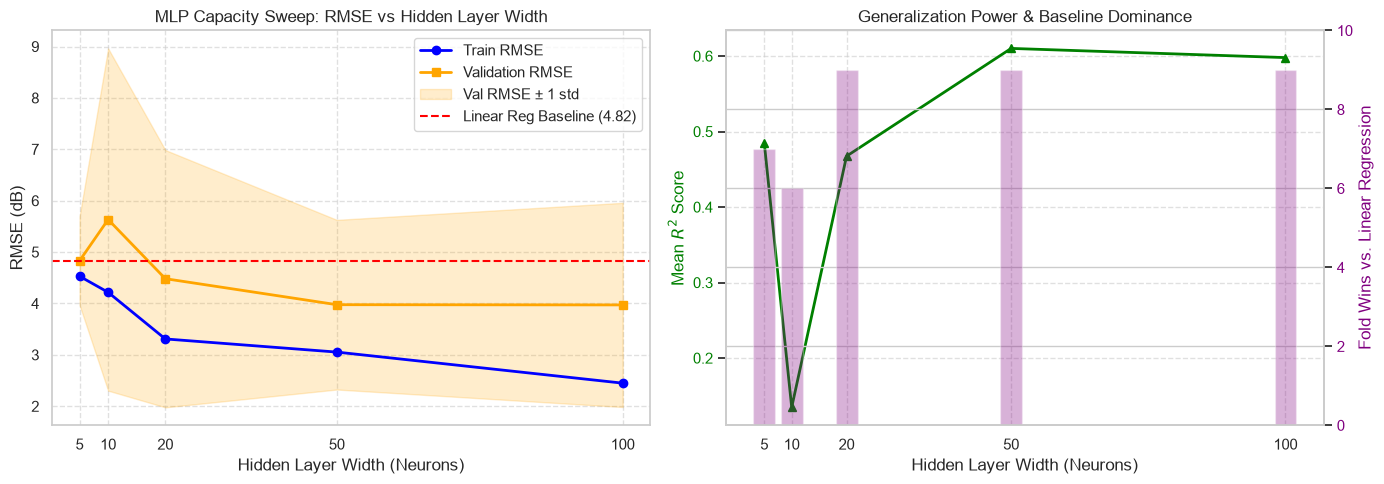

In [12]:
widths = [5, 10, 20, 50, 100]
sweep_rows = []

gkf = GroupKFold(n_splits=10)

for fold, (tr_idx, va_idx) in enumerate(gkf.split(X_train_val, y_train_val, groups=groups[train_val_idx])):
    X_sw_train, X_sw_val = X_train_val.iloc[tr_idx], X_train_val.iloc[va_idx]
    y_sw_train, y_sw_val = y_train_val.iloc[tr_idx], y_train_val.iloc[va_idx]

    # Linear regression on the same fold, as the reference for this fold
    lr_sw = LinearRegression()
    lr_sw.fit(X_sw_train, y_sw_train)
    lr_rmse = regression_metrics(y_sw_val, lr_sw.predict(X_sw_val))["RMSE"]

    for w in widths:
        model_w = make_pipeline(StandardScaler(), make_mlp(hidden_layer_sizes=(w,)))

        start = time.perf_counter()
        model_w.fit(X_sw_train, y_sw_train)
        fit_time = time.perf_counter() - start

        train_scores = regression_metrics(y_sw_train, model_w.predict(X_sw_train))
        val_scores = regression_metrics(y_sw_val, model_w.predict(X_sw_val))

        sweep_rows.append({
            "fold": fold,
            "width": w,
            "train_RMSE": train_scores["RMSE"],
            "val_RMSE": val_scores["RMSE"],
            "val_R2": val_scores["R2"],
            "lr_val_RMSE": lr_rmse,
            "fit_time_s": fit_time,
        })

sweep_results = pd.DataFrame(sweep_rows)

# Does the MLP beat linear regression on this fold? (True = MLP better)
sweep_results["beats_lr"] = sweep_results["val_RMSE"] < sweep_results["lr_val_RMSE"]

# One row per width: mean and std across the 5 folds
sweep_summary = sweep_results.groupby("width").agg(
    train_RMSE_mean=("train_RMSE", "mean"),
    val_RMSE_mean=("val_RMSE", "mean"),
    val_RMSE_std=("val_RMSE", "std"),
    val_R2_mean=("val_R2", "mean"),
    wins_vs_lr=("beats_lr", "sum"),
    fit_time_mean=("fit_time_s", "mean"),
)
sweep_summary["parameters"] = 7 * sweep_summary.index + 1

display(sweep_summary)

# The folds where the MLP lost to linear regression
display(sweep_results[~sweep_results["beats_lr"]])

# Create a figure with 2 subplots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- PLOT 1: Train vs Validation RMSE (The Bias-Variance Curve) ---
ax1 = axes[0]
ax1.plot(
    sweep_summary.index,
    sweep_summary["train_RMSE_mean"],
    marker="o",
    label="Train RMSE",
    color="blue",
    linewidth=2,
)

# Plot validation RMSE with error shading (± 1 standard deviation)
ax1.plot(
    sweep_summary.index,
    sweep_summary["val_RMSE_mean"],
    marker="s",
    label="Validation RMSE",
    color="orange",
    linewidth=2,
)
ax1.fill_between(
    sweep_summary.index,
    sweep_summary["val_RMSE_mean"] - sweep_summary["val_RMSE_std"],
    sweep_summary["val_RMSE_mean"] + sweep_summary["val_RMSE_std"],
    color="orange",
    alpha=0.2,
    label="Val RMSE ± 1 std",
)

# Draw a horizontal reference line for Linear Regression's validation performance
# (Averaging the lr_val_RMSE across all runs for a flat baseline comparison)
mean_lr_rmse = sweep_results["lr_val_RMSE"].mean()
ax1.axhline(
    y=mean_lr_rmse,
    color="red",
    linestyle="--",
    label=f"Linear Reg Baseline ({mean_lr_rmse:.2f})",
)

ax1.set_title("MLP Capacity Sweep: RMSE vs Hidden Layer Width")
ax1.set_xlabel("Hidden Layer Width (Neurons)")
ax1.set_ylabel("RMSE (dB)")
ax1.set_xticks(sweep_summary.index)
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend(loc="upper right")

# --- PLOT 2: Wins vs Linear Regression & Generalization ($R^2$) ---
ax2 = axes[1]
ax2.plot(
    sweep_summary.index,
    sweep_summary["val_R2_mean"],
    marker="^",
    color="green",
    linewidth=2,
    label="Validation R²",
)
ax2.set_ylabel("Mean $R^2$ Score", color="green")
ax2.tick_params(axis="y", labelcolor="green")

# Create a twin axis to show how many folds it beat Linear Regression on
ax3 = ax2.twinx()
ax3.bar(
    sweep_summary.index,
    sweep_summary["wins_vs_lr"],
    alpha=0.3,
    color="purple",
    width=4,
    label="Wins vs Linear Reg (out of total folds)",
)
ax3.set_ylabel("Fold Wins vs. Linear Regression", color="purple")
ax3.tick_params(axis="y", labelcolor="purple")
# Note: Your code used n_splits=10 in the loop, so max wins is 10
ax3.set_ylim(0, 10)

ax2.set_title("Generalization Power & Baseline Dominance")
ax2.set_xlabel("Hidden Layer Width (Neurons)")
ax2.set_xticks(sweep_summary.index)
ax2.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

In [13]:
# Include the mean baseline alongside your other models
final_models = {
    "Mean Baseline": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "MLP (Width 50)": make_pipeline(
        StandardScaler(), make_mlp(hidden_layer_sizes=(50,))
    ),
}

results = []

for name, m in final_models.items():
  # Train on the combined train+val set
  m.fit(X_train_val, y_train_val)

  # Compute metrics
  preds = m.predict(X_test)
  metrics = regression_metrics(y_test, preds)
  metrics["Model"] = name
  results.append(metrics)

  # Measure inference time programmatically
  start_time = time.perf_counter()
  _ = m.predict(X_test)
  end_time = time.perf_counter()
  print(f"{name} inference time: {(end_time - start_time)*1000:.3f} ms")

# Display results cleanly in a DataFrame
results_df = pd.DataFrame(results).set_index("Model")
display(results_df)

Mean Baseline inference time: 0.042 ms
Linear Regression inference time: 0.559 ms
MLP (Width 50) inference time: 1.027 ms


,MAE,RMSE,R2
Model,,,
Mean Baseline,5.6788,7.1518,-0.0530
Linear Regression,3.6947,4.9780,0.4898
MLP (Width 50),3.0375,3.9612,0.6769
